# Titanic: un albero, tre letture, quattro tipi di feature

Questo notebook costruisce alberi di decisione sul Titanic usando **una feature per tipo** e legge ogni albero in tre modi:

1. **diagramma** (nodi, archi, foglie);
2. **insieme di regole** (un cammino radice → foglia = una regola);
3. **partizione dello spazio degli input** (ogni foglia = una regione).

| Tipo | Feature | Test nel nodo | Menu di split in un nodo ($k$ valori distinti) |
|---|---|---|---|
| continua | `Age` | `Age ≤ t` | $k-1$ |
| discreta ordinata (ordinale) | `Pclass` | `Pclass ≤ t` | $k-1$ |
| nominale | `Title` (Mr, Mrs, Miss, Master, Other) | `Title ∈ S` | $2^{k-1}-1$ |
| identificativo ad alta cardinalità | `PassengerId` | dipende da come lo si dichiara | enorme |

**Perché un CART scritto a mano.** `DecisionTreeClassifier` di scikit-learn fa solo split a soglia, quindi `Title` andrebbe codificata (one-hot o ordinale) e la codifica deciderebbe quali gruppi sono raggiungibili. [`mini_cart.py`](mini_cart.py) invece riceve il tipo di ogni feature: soglie per le ordinate, sottoinsiemi per le nominali. Per le nominali usa il trucco di Breiman: ordina le categorie per tasso di sopravvivenza e prova i $k-1$ prefissi, che per un target binario e il Gini contengono sempre lo split migliore fra tutti i $2^{k-1}-1$.

Il **menu** è l'insieme delle domande fra cui l'algoritmo sceglie la domanda di **un singolo nodo**. Non è il numero di domande nell'albero.

Teoria di riferimento: `../xai-2025-2026-cookbook/appunti/decision_tree_tipi_di_feature.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from mini_cart import MiniCART
from tree_plots import plot_tree, plot_partition_age_pclass, plot_id_barcode, DIED, SURVIVED

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("../data/titanic.csv")
title = df["Name"].str.extract(r",\s*([^.]+)\.")[0].str.strip()
df["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Other")

# MiniCART non gestisce i mancanti: teniamo i passeggeri con età nota
print(f"passeggeri totali: {len(df)}, senza Age: {df['Age'].isna().sum()}")
df = df.dropna(subset=["Age"]).reset_index(drop=True)

train, test = train_test_split(df, test_size=0.3, stratify=df["Survived"], random_state=0)
print(f"usati: {len(df)}  →  training {len(train)}, test {len(test)}")
df[["PassengerId", "Age", "Pclass", "Title", "Survived"]].head()

passeggeri totali: 891, senza Age: 177
usati: 714  →  training 499, test 215


,PassengerId,Age,Pclass,Title,Survived
0,1,22.0,3,Mr,0
1,2,38.0,1,Mrs,1
2,3,26.0,3,Miss,1
3,4,35.0,1,Mrs,1
4,5,35.0,3,Mr,0


## 1. Le quattro feature

Il tipo dipende dal **significato**, non da come la colonna è memorizzata: `Pclass` e `PassengerId` sono entrambe interi, ma solo la prima ha un ordine che significa qualcosa.

In [2]:
pd.DataFrame({
    "feature": ["Age", "Pclass", "Title", "PassengerId"],
    "tipo": ["continua", "ordinale", "nominale", "identificativo"],
    "valori distinti (training)": [train[c].nunique() for c in ["Age", "Pclass", "Title", "PassengerId"]],
    "esempi di valori": [sorted(train[c].unique())[:5] for c in ["Age", "Pclass", "Title", "PassengerId"]],
})

,feature,tipo,valori distinti (training),esempi di valori
0,Age,continua,83,"[0.42, 0.67, 0.75, 0.83, 0.92]"
1,Pclass,ordinale,3,"[1, 2, 3]"
2,Title,nominale,5,"[Master, Miss, Mr, Mrs, Other]"
3,PassengerId,identificativo,499,"[3, 4, 5, 7, 8]"


In [3]:
# tasso di sopravvivenza per Title: è l'ordine che il trucco di Breiman usa per la nominale
(train.groupby("Title")["Survived"].agg(vivi="sum", passeggeri="count", tasso="mean")
      .sort_values("tasso").round(3))

,vivi,passeggeri,tasso
Title,,,
Mr,45,268,0.168
Other,9,19,0.474
Master,18,28,0.643
Miss,72,104,0.692
Mrs,59,80,0.738


## 2. Albero A: `Age` (continua), `Pclass` (ordinale), `Title` (nominale)

### 2.1 Il menu alla radice

Per ciascuna feature: quante domande diverse si potrebbero mettere **nel nodo radice** e qual è la migliore. `Title` ha un menu completo di $2^{5-1}-1 = 15$ voci, ma ne valutiamo 4 (trucco di Breiman) senza perdere l'ottimo. Vince `Title ∈ {Mr}`, che ha il Gini pesato più basso.

In [4]:
types_A = {"Age": "ordered", "Pclass": "ordered", "Title": "nominal"}
tree_A = MiniCART(types_A, max_depth=3, min_samples_leaf=5).fit(train, train["Survived"])
tree_A.candidate_splits(train, train["Survived"])

,feature,tipo,valori distinti k,menu completo,voci valutate,miglior split,Gini pesato
0,Age,ordered,83,82,82,Age ≤ 6.5,0.4659
1,Pclass,ordered,3,2,2,Pclass ≤ 2.5,0.4268
2,Title,nominal,5,15,4,Title ∈ {Mr},0.3502


### 2.2 Lettura 1: diagramma

Ramo sinistro = condizione vera ("sì"). Le tre feature producono test di forma diversa:

- `Age ≤ 32.25`: soglia su una continua, punto medio fra due età osservate;
- `Pclass ≤ 1.5`: soglia su un'ordinale; il ",5" non è un numero vero, significa "classe 1" contro "classe 2 o 3";
- `Title ∈ {Mr}`: appartenenza a un sottoinsieme; nessun ordine fra i titoli.

`Title` compare **due volte** sullo stesso cammino (radice e livello 3). Con gli split binari su sottoinsiemi una nominale si può riusare per separare valori rimasti insieme: prima {Mr} contro il resto, poi {Other} contro {Master, Miss, Mrs}.

In [5]:
print(tree_A.to_text())

radice [morti 296, vivi 203]
├── Title ∈ {Mr}
│   ├── Pclass ≤ 1.5
│   │   ├── Age ≤ 45.5  →  foglia 3: NON SOPRAVVIVE [morti 18, vivi 17]
│   │   └── Age > 45.5  →  foglia 4: NON SOPRAVVIVE [morti 19, vivi 3]
│   └── Pclass > 1.5
│       ├── Age ≤ 32.25  →  foglia 6: NON SOPRAVVIVE [morti 120, vivi 23]
│       └── Age > 32.25  →  foglia 7: NON SOPRAVVIVE [morti 66, vivi 2]
└── Title ∉ {Mr}
    ├── Pclass ≤ 2.5
    │   ├── Title ∈ {Other}  →  foglia 10: NON SOPRAVVIVE [morti 10, vivi 9]
    │   └── Title ∉ {Other}  →  foglia 11: SOPRAVVIVE [morti 8, vivi 112]
    └── Pclass > 2.5
        ├── Age ≤ 38.5  →  foglia 13: NON SOPRAVVIVE [morti 45, vivi 36]
        └── Age > 38.5  →  foglia 14: NON SOPRAVVIVE [morti 10, vivi 1]


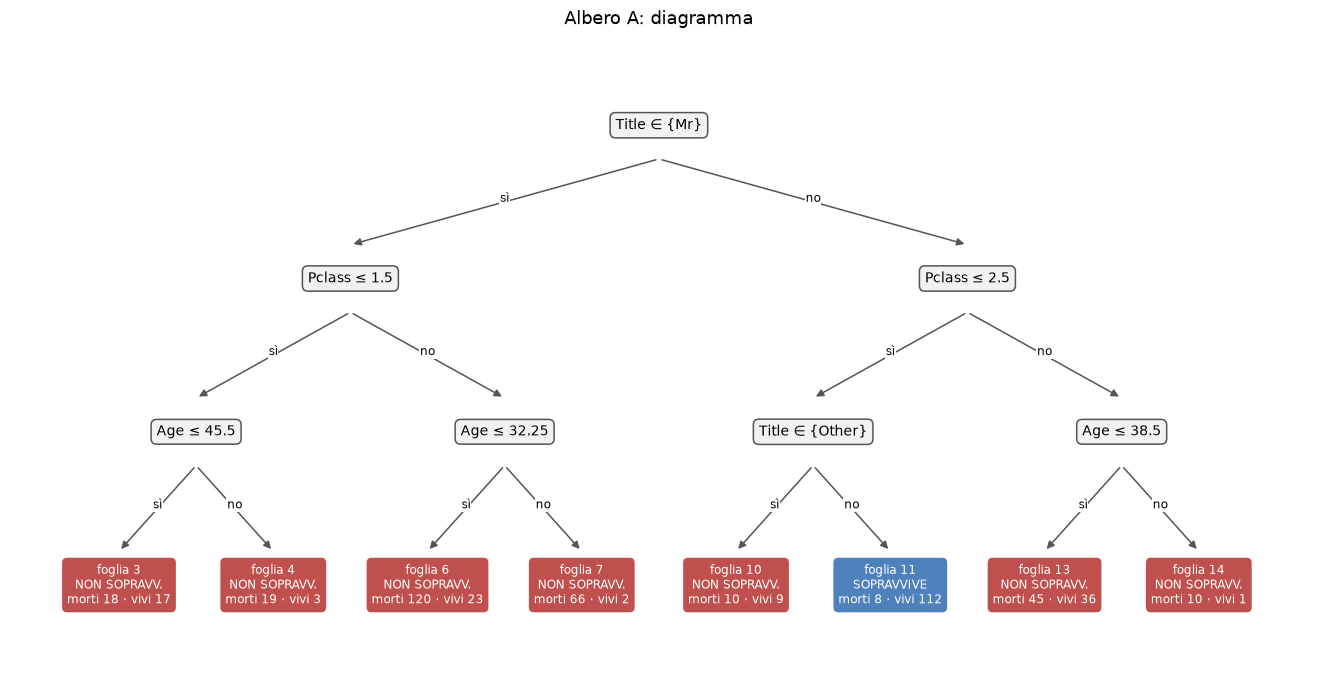

In [6]:
plot_tree(tree_A, title="Albero A: diagramma")
plt.show()

### 2.3 Lettura 2: regole

Ogni foglia è una regola; le condizioni sullo stesso cammino sono in AND. Le condizioni sulla **stessa feature** si fondono:

- per le ordinate in un **intervallo** (`Age ≤ 45.5`, `Pclass > 1.5`, …);
- per la nominale in un **insieme** (`Title ∉ {Mr}` e poi `Title ∉ {Other}` diventano `Title ∈ {Master, Miss, Mrs}`).

Le regole sono mutuamente esclusive ed esaustive: ogni passeggero ne soddisfa esattamente una.

In [7]:
rules_A = tree_A.rules()
rules_A

,foglia,regola,predizione,morti,vivi,accuratezza
0,3,Title ∈ {Mr} AND Pclass ≤ 1.5 AND Age ≤ 45.5,non sopravvive,18,17,0.514
1,4,Title ∈ {Mr} AND Pclass ≤ 1.5 AND Age > 45.5,non sopravvive,19,3,0.864
2,6,Title ∈ {Mr} AND Pclass > 1.5 AND Age ≤ 32.25,non sopravvive,120,23,0.839
3,7,Title ∈ {Mr} AND Pclass > 1.5 AND Age > 32.25,non sopravvive,66,2,0.971
4,10,Title ∈ {Other} AND Pclass ≤ 2.5,non sopravvive,10,9,0.526
5,11,"Title ∈ {Master, Miss, Mrs} AND Pclass ≤ 2.5",sopravvive,8,112,0.933
6,13,"Title ∈ {Master, Miss, Mrs, Other} AND Pclass > 2.5 AND Age ≤ 38.5",non sopravvive,45,36,0.556
7,14,"Title ∈ {Master, Miss, Mrs, Other} AND Pclass > 2.5 AND Age > 38.5",non sopravvive,10,1,0.909


Alcune coppie di foglie sorelle hanno la stessa predizione, ad esempio le foglie 3 e 4, entrambe "non sopravvive". Lo split non cambia la classe ma rende i figli più puri: la foglia 4 (uomini di prima classe con più di 45 anni) è all'86% "non sopravvive", la foglia 3 è quasi metà e metà. Il Gini premia questa separazione anche se la predizione non cambia.

### 2.4 Lettura 3: partizione dello spazio degli input

Lo spazio ha tre dimensioni (`Age`, `Pclass`, `Title`). Lo disegniamo come **un pannello per ogni valore di `Title`**, e in ciascun pannello il piano (`Age`, `Pclass`). Ogni rettangolo bordato è un pezzo di regione (colore = classe predetta, `fN` = numero della foglia; una foglia può occupare più righe o più pannelli); i punti sono i passeggeri di training (colore = esito reale).

Come appare ciascun tipo di feature:

- **`Age` (continua)**: i confini sono **rette verticali** in un punto qualsiasi dell'asse (32,25; 38,5; 45,5).
- **`Pclass` (ordinale)**: i dati stanno su **tre righe**; i confini cadono *fra* una riga e l'altra, e il valore esatto della soglia (1,5 o 1,9) non cambia nulla.
- **`Title` (nominale)**: non c'è un asse, quindi un pannello per valore. La regione lungo `Title` è un **insieme di pannelli**. Master, Miss e Mrs hanno partizioni identiche perché stanno sempre nello stesso sottoinsieme; Other differisce solo per le classi 1–2.
- **Gerarchia**: il taglio `Age ≤ 32.25` esiste solo nel pannello Mr e solo per le classi 2–3. Un taglio vale solo dentro la regione del suo nodo.

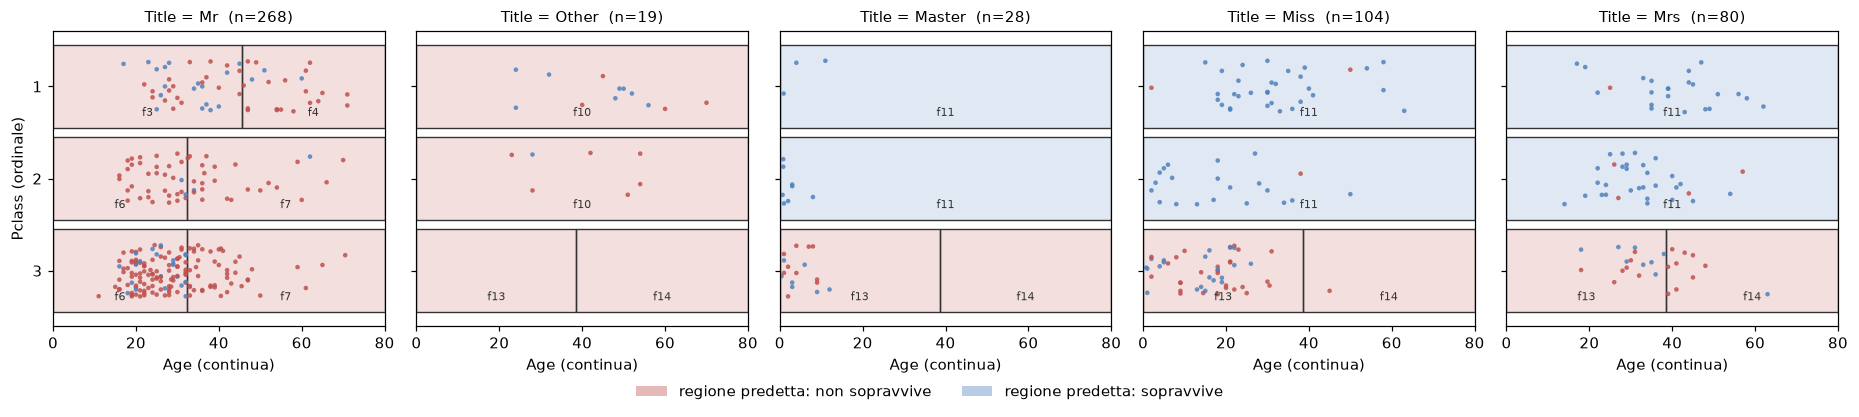

In [8]:
fig = plot_partition_age_pclass(tree_A, train, ["Mr", "Other", "Master", "Miss", "Mrs"])
plt.show()

In [9]:
print(f"Albero A: accuratezza training {tree_A.score(train, train['Survived']):.3f}, "
      f"test {tree_A.score(test, test['Survived']):.3f}")

Albero A: accuratezza training 0.802, test 0.791


## 3. Albero B: aggiungiamo `PassengerId` come **nominale**

`PassengerId` è un'etichetta, quindi dichiararlo nominale sembra corretto. Ha 499 valori distinti nel training: il menu completo alla radice ha $2^{498}$ voci circa, cioè circa $10^{149}$.

Ogni ID corrisponde a un solo passeggero, quindi il suo "tasso di sopravvivenza" è 0 o 1. Ordinando gli ID per tasso, il prefisso "tutti gli ID dei morti" separa **perfettamente** il training: Gini pesato **0**. Nessun'altra feature può battere questo valore.

In [10]:
types_B = {**types_A, "PassengerId": "nominal"}
tree_B = MiniCART(types_B, max_depth=3, min_samples_leaf=5).fit(train, train["Survived"])
tree_B.candidate_splits(train, train["Survived"])

,feature,tipo,valori distinti k,menu completo,voci valutate,miglior split,Gini pesato
0,Age,ordered,83,82,82,Age ≤ 6.5,0.4659
1,Pclass,ordered,3,2,2,Pclass ≤ 2.5,0.4268
2,Title,nominal,5,15,4,Title ∈ {Mr},0.3502
3,PassengerId,nominal,499,≈ 10^149,498,"PassengerId ∈ {5, 7, 8, … (296 valori)}",0.0000


### 3.1 Diagramma e regole

L'albero si ferma alla radice: un solo nodo, due foglie pure. Le regole "memorizzano" l'elenco dei morti e dei sopravvissuti.

radice [morti 296, vivi 203]
├── PassengerId ∈ {5, 7, 8, … (296 valori)}  →  foglia 1: NON SOPRAVVIVE [morti 296, vivi 0]
└── PassengerId ∉ {5, 7, 8, … (296 valori)}  →  foglia 2: SOPRAVVIVE [morti 0, vivi 203]


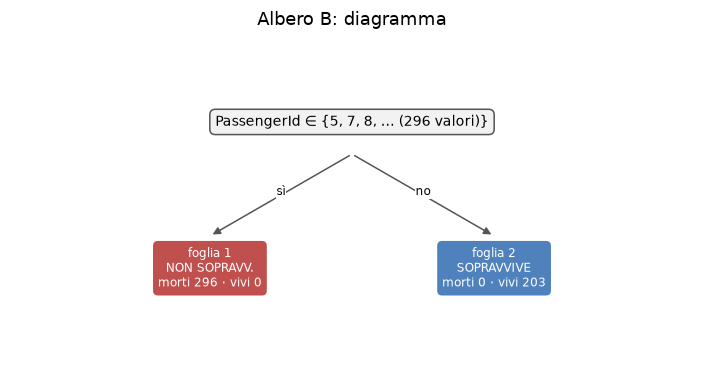

,foglia,regola,predizione,morti,vivi,accuratezza
0,1,"PassengerId ∈ {5, 7, 8, … (296 valori)}",non sopravvive,296,0,1.0
1,2,"PassengerId ∈ {3, 4, 10, … (203 valori)}",sopravvive,0,203,1.0


In [11]:
print(tree_B.to_text())
plot_tree(tree_B, title="Albero B: diagramma")
plt.show()
tree_B.rules()

### 3.2 Partizione: un codice a barre

Lungo l'asse `PassengerId` la regione di ciascuna foglia è un insieme sparso di punti, senza alcuna struttura (riga in alto). Un passeggero di test ha un ID **mai visto**, quindi non appartiene né all'insieme della foglia 1 né, propriamente, a quello della foglia 2. MiniCART lo manda nel ramo con più esempi di training (scelta dichiarata, non appresa): tutti i passeggeri di test vengono predetti "non sopravvive" (riga in basso, tutta rossa).

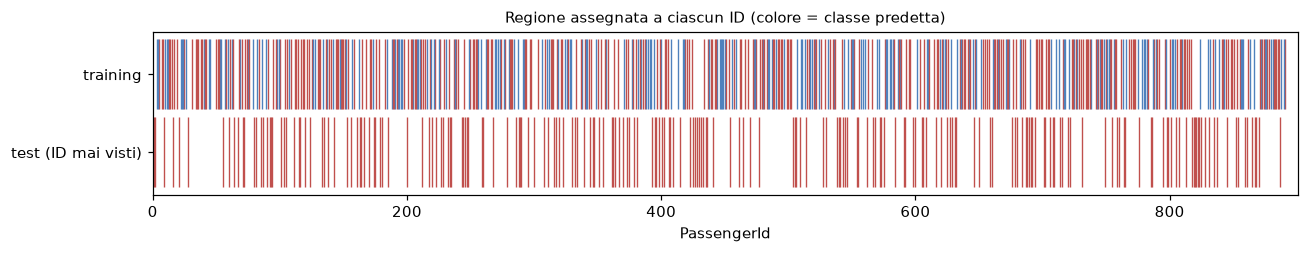

Albero B: accuratezza training 1.000, test 0.595
quota di non sopravvissuti nel test: 0.595


In [12]:
fig = plot_id_barcode(tree_B, train, test)
plt.show()
print(f"Albero B: accuratezza training {tree_B.score(train, train['Survived']):.3f}, "
      f"test {tree_B.score(test, test['Survived']):.3f}")
print(f"quota di non sopravvissuti nel test: {1 - test['Survived'].mean():.3f}")

Accuratezza 1,000 sul training e, sul test, esattamente la quota di non sopravvissuti: il modello non ha imparato nulla. È il caso limite della trappola dell'information gain (e del Gini) verso le feature con molti valori: l'identificativo vince la radice perché rende ogni foglia pura, non perché spieghi qualcosa.

## 4. Albero C: `PassengerId` come **numero** (quello che farebbe scikit-learn)

Se lasciamo `PassengerId` come intero, lo split è una soglia e il menu ha solo $k-1 = 498$ voci. Ogni taglio divide gli ID in "prima" e "dopo", un ordine che non significa nulla. Con questo split train/test e profondità 3 l'ID non viene scelto e l'albero coincide con l'albero A. A profondità 4, nei nodi piccoli, compare 4 volte: con pochi esempi un taglio qualsiasi trova per caso due gruppi un po' più puri.

In [13]:
types_C = {**types_A, "PassengerId": "ordered"}
tree_A4 = MiniCART(types_A, max_depth=4, min_samples_leaf=5).fit(train, train["Survived"])
tree_C = MiniCART(types_C, max_depth=4, min_samples_leaf=5).fit(train, train["Survived"])
print(tree_C.to_text())

radice [morti 296, vivi 203]
├── Title ∈ {Mr}
│   ├── Pclass ≤ 1.5
│   │   ├── Age ≤ 45.5
│   │   │   ├── PassengerId ≤ 384.5  →  foglia 4: NON SOPRAVVIVE [morti 13, vivi 7]
│   │   │   └── PassengerId > 384.5  →  foglia 5: SOPRAVVIVE [morti 5, vivi 10]
│   │   └── Age > 45.5
│   │       ├── PassengerId ≤ 572  →  foglia 7: NON SOPRAVVIVE [morti 15, vivi 0]
│   │       └── PassengerId > 572  →  foglia 8: NON SOPRAVVIVE [morti 4, vivi 3]
│   └── Pclass > 1.5
│       ├── Age ≤ 32.25
│       │   ├── Age ≤ 28.75  →  foglia 11: NON SOPRAVVIVE [morti 96, vivi 12]
│       │   └── Age > 28.75  →  foglia 12: NON SOPRAVVIVE [morti 24, vivi 11]
│       └── Age > 32.25
│           ├── Age ≤ 61.5  →  foglia 14: NON SOPRAVVIVE [morti 62, vivi 1]
│           └── Age > 61.5  →  foglia 15: NON SOPRAVVIVE [morti 4, vivi 1]
└── Title ∉ {Mr}
    ├── Pclass ≤ 2.5
    │   ├── Title ∈ {Other}
    │   │   ├── PassengerId ≤ 421.5  →  foglia 19: NON SOPRAVVIVE [morti 6, vivi 0]
    │   │   └── PassengerId > 421.

In [14]:
rules_C = tree_C.rules()
rules_C[rules_C["regola"].str.contains("PassengerId")]

,foglia,regola,predizione,morti,vivi,accuratezza
0,4,Title ∈ {Mr} AND Pclass ≤ 1.5 AND Age ≤ 45.5 AND PassengerId ≤ 384.5,non sopravvive,13,7,0.650
1,5,Title ∈ {Mr} AND Pclass ≤ 1.5 AND Age ≤ 45.5 AND PassengerId > 384.5,sopravvive,5,10,0.667
2,7,Title ∈ {Mr} AND Pclass ≤ 1.5 AND Age > 45.5 AND PassengerId ≤ 572,non sopravvive,15,0,1.000
3,8,Title ∈ {Mr} AND Pclass ≤ 1.5 AND Age > 45.5 AND PassengerId > 572,non sopravvive,4,3,0.571
8,19,Title ∈ {Other} AND Pclass ≤ 2.5 AND PassengerId ≤ 421.5,non sopravvive,6,0,1.000
9,20,Title ∈ {Other} AND Pclass ≤ 2.5 AND PassengerId > 421.5,sopravvive,4,9,0.692
12,26,"Title ∈ {Master, Miss, Mrs, Other} AND Pclass > 2.5 AND Age ≤ 38.5 AND PassengerId ≤ 384.5",sopravvive,17,22,0.564
13,27,"Title ∈ {Master, Miss, Mrs, Other} AND Pclass > 2.5 AND Age ≤ 38.5 AND PassengerId > 384.5",non sopravvive,28,14,0.667


Regole come "`Title ∈ {Mr}` AND `Pclass ≤ 1.5` AND `Age ≤ 45.5` AND `PassengerId > 384.5` → sopravvive" sono sintatticamente perfette e semanticamente vuote: nessuno saprebbe spiegare a un utente perché l'ordine di registrazione dovrebbe contare.

Nella partizione questi tagli sono rette perpendicolari all'asse `PassengerId`. Ecco il nodo `Title ∉ {Mr}`, `Pclass = 3`, `Age ≤ 38.5`: il taglio a 384,5 separa due gruppi che differiscono solo per caso.

PassengerId ≤ 384.5: n=39, tasso sopravvivenza=0.564
PassengerId > 384.5: n=42, tasso sopravvivenza=0.333


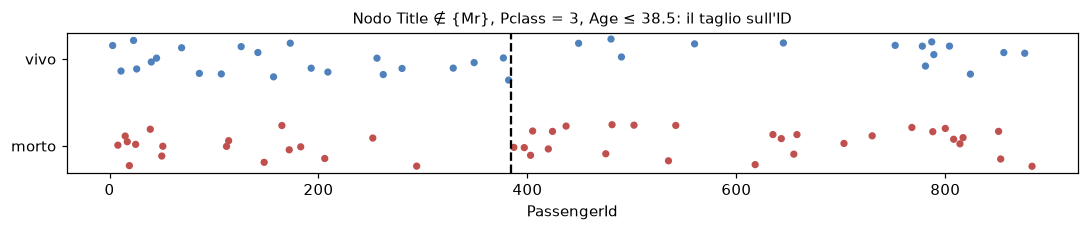

In [15]:
node = train[(train["Title"] != "Mr") & (train["Pclass"] == 3) & (train["Age"] <= 38.5)]
fig, ax = plt.subplots(figsize=(10, 2.2))
jit = np.random.default_rng(1).uniform(-0.25, 0.25, len(node))
ax.scatter(node["PassengerId"], node["Survived"] + jit, s=14,
           c=np.where(node["Survived"] == 1, SURVIVED, DIED))
ax.axvline(384.5, color="k", ls="--")
for side, part in (("≤ 384.5", node[node["PassengerId"] <= 384.5]), ("> 384.5", node[node["PassengerId"] > 384.5])):
    print(f"PassengerId {side}: n={len(part)}, tasso sopravvivenza={part['Survived'].mean():.3f}")
ax.set_yticks([0, 1]); ax.set_yticklabels(["morto", "vivo"]); ax.set_xlabel("PassengerId")
ax.set_title("Nodo Title ∉ {Mr}, Pclass = 3, Age ≤ 38.5: il taglio sull'ID", fontsize=10)
fig.tight_layout(); plt.show()

Su un singolo train/test split il confronto con l'albero senza ID è rumoroso. Ripetiamo con 50 split casuali, profondità 4.

In [16]:
rows = []
for seed in range(50):
    tr, te = train_test_split(df, test_size=0.3, stratify=df["Survived"], random_state=seed)
    for name, types in (("A: Age, Pclass, Title", types_A),
                        ("C: + PassengerId numerico", types_C),
                        ("B: + PassengerId nominale", types_B)):
        m = MiniCART(types, max_depth=4, min_samples_leaf=5).fit(tr, tr["Survived"])
        used = sum(1 for n in m.nodes() if not n.is_leaf and n.split.feature == "PassengerId")
        rows.append({"albero": name, "seed": seed, "training": m.score(tr, tr["Survived"]),
                     "test": m.score(te, te["Survived"]), "nodi su PassengerId": used})
res = pd.DataFrame(rows)
summary = res.groupby("albero", sort=False).agg(
    training=("training", "mean"), test=("test", "mean"), test_std=("test", "std"),
    nodi_ID=("nodi su PassengerId", "mean")).round(3)
summary

,training,test,test_std,nodi_ID
albero,,,,
"A: Age, Pclass, Title",0.824,0.783,0.018,0.00
C: + PassengerId numerico,0.833,0.783,0.023,4.82
B: + PassengerId nominale,1.000,0.595,0.000,1.00


In [17]:
wide = res.pivot(index="seed", columns="albero", values="test")
diff = wide["C: + PassengerId numerico"] - wide["A: Age, Pclass, Title"]
print(f"C - A sul test: media {diff.mean():+.4f}; C migliore in {(diff > 0).sum()}/50 split, "
      f"peggiore in {(diff < 0).sum()}/50")

C - A sul test: media -0.0001; C migliore in 23/50 split, peggiore in 21/50


L'ID numerico alza un po' l'accuratezza di **training** e lascia invariata, in media, quella di **test**: è rumore che l'albero adatta. L'ID nominale porta il training a 1 e il test alla quota della classe maggioritaria.

## 5. Sintesi

| Feature | Tipo | Forma del test | Menu alla radice | Regione lungo la feature | Effetto |
|---|---|---|---|---|---|
| `Age` | continua | `Age ≤ t` | $k-1 = 82$ | intervallo | tagli verticali dove servono |
| `Pclass` | ordinale | `Pclass ≤ 1.5 / 2.5` | $k-1 = 2$ | classi consecutive | tagli fra righe del reticolo; {1, 3} \| {2} impossibile |
| `Title` | nominale | `Title ∈ S` | $2^{4}-1 = 15$ (4 valutate) | insieme di valori (pannelli) | riusabile sullo stesso cammino; nessun asse |
| `PassengerId` nominale | identificativo | `PassengerId ∈ S` | $\approx 10^{149}$ (498 valutate) | insieme sparso (codice a barre) | Gini 0 alla radice, test = classe maggioritaria |
| `PassengerId` numerico | identificativo | `PassengerId ≤ t` | $k-1 = 498$ | intervallo di ID senza significato | tagli casuali nei nodi piccoli, nessun guadagno sul test |

**Da ricordare.**

- Il tipo della feature decide la **forma del test** (soglia o appartenenza), la dimensione del **menu** per un nodo ($k-1$ o $2^{k-1}-1$) e la **forma della regione** (intervallo o insieme).
- Le tre letture sono lo stesso oggetto: un cammino nel diagramma è una regola ed è una regione.
- Un identificativo va eliminato o trasformato *prima* dell'albero: nominale porta a memorizzare il training, numerico a regole senza significato.